# 0. Pemahaman Bisnis

## 0.1 Konteks (Mohon Baca Ini Sebelum Memulai)

### 0.1.1 Apa itu Fraud Credit Card?

Fraud kartu kredit terjadi ketika kartu kredit atau informasi kartu kredit digunakan oleh pihak yang tidak berwenang untuk melakukan transaksi tanpa persetujuan pemilik kartu.

### 0.1.2 Bagaimana perkiraan proses bisnis umum transaksi menggunakan kartu kredit?

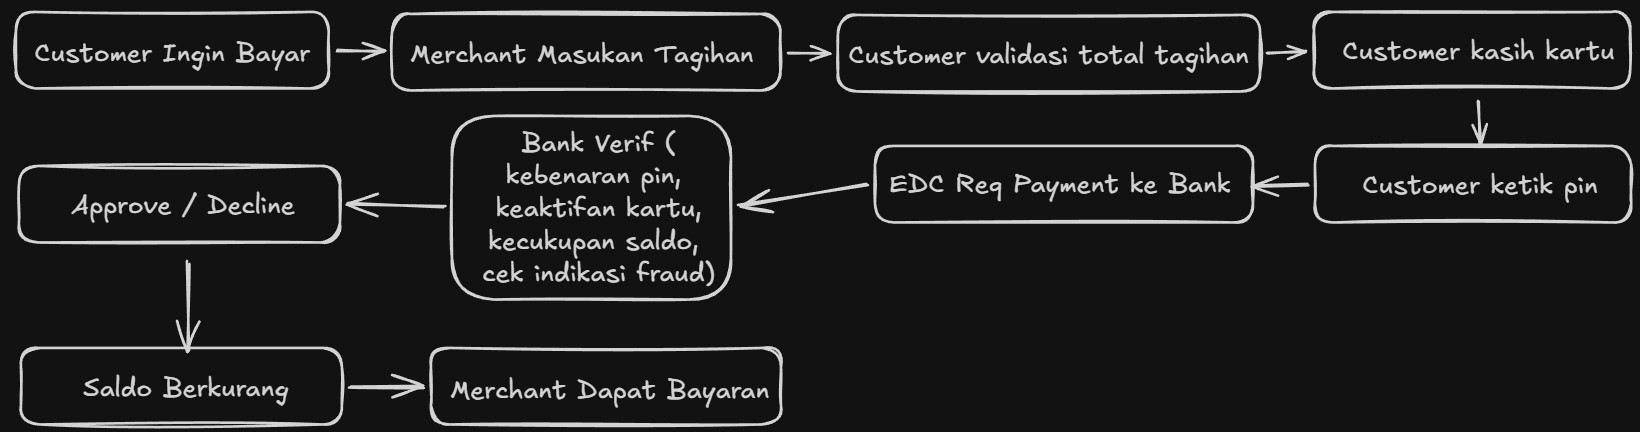

Notes : Karena minimnya pengetahuan dan pengalaman pembuat, proses bisnis diatas merupakan gabungan hasil pemahaman dari berbagai sumber baca yang tersedia

### 0.1.3 Berapa perbandingan Fraud : Non Fraud berdasarkan fakta yang diberikan?

Berdasarkan fakta yang diberikan, pada dataset (Kondisi Kotor) terdapat 492 kasus fraud dengan class 0 dari total data 284.807 dan 283.315 kasus non fraud dengan class 1

### 0.1.4 Apakah ada catatan khusus terkait feature dari penyedia data?

Feature Time itu hasil selisih dari baris ke n - baris pertama

### 0.1.5 Apakah ada parameter output khusus yang diminta penyedia data?

Permintaan nya berupa parameter penilaian yang dipakai harus Precision-Recall Curve (AUPRC) sejalan dengan kondisi class imbalance

### 0.1.6 Jika Fraud terjadi pihak mana saja yang mengalami kerugian?

Beberapa pihak yang mengalami kerugian:
- Bank, karena harus menanggung kerugian yang terjadi atau bahkan kemungkinan bisa kehilangan kepercayaan nasabah
- Nasabah, karena perlu menanggung kerugian yang bukan atas kehendaknya
- Merchant, dalam beberapa kasus fraud dapat dibuktikan apakah terjadi kelalaian pada pihak merchant atau tidak sehingga bisa terjadi merchant menanggung kerugian dari kasus fraud yang terjadi

## 0.2 Data Question


Beberapa hal yang perlu dipastikan dan terjawab dari hasil pengerjaan tahap 1, antara lain:
- Bagaimana karakteristik data? apakah long atau width?
- Apakah terdapat indikasi bahwa satu baris mewakili 1 event? tidak ada 1 event yang tercatat pada lebih dari 1 baris?
- Apa saja list kerusakan data yang perlu diperbaiki? (Null, Duplicate, Outlier, Invalid Values, Invalid Dtypes, Inconsistency)
- Distribusi Data nya gimana?
- Bagaimana Variansi antar feature nya?

### 0.2.3 DATA QUESTION

Q9  : Tipe data long atau width? \
A9  : Sejalan dengan ga ada nya ID, gabisa dipastikan apakah data long atau width, tidak ada kolom yang menunjukan urutan kejadian juga. Jadi di asumsikan bahwa data width\
\
Q10 : Satu baris mewakili apa? \
A10 : Tidak bisa dipastikan tapi yang jelas ada kejadian duplicated time. Bisa diartikan memang ada 2 orang atau lebih yang melakukan transaksi pada waktu yang sama atau memang terjadi error system atau mesin.

# 1. Import Library, Data, dan Memastikan Data Berhasil di Import

In [91]:
# import Library

import pandas as pd
import matplotlib.pyplot as plt

In [92]:
# Import Data

path_data = r'..\Data\creditcard.csv'

In [93]:
# Panggil Data

df_fraud = pd.read_csv(path_data)

In [94]:
# Pastiin Data Berhasil di Import

df_fraud.head(2)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0


In [95]:
df_fraud.shape

(284807, 31)

Kesimpulan : Data sudah berhasil di import tanpa masalah. Hal ini didukung dari kondisi data saat dipanggil sudah terpisahkan untuk tiap kolom dan baris

# 2. Cari Jawaban Terkait Poin Data Question

## 2.1 Bagaimana karakteristik data? apakah long atau width?

In [96]:
df_fraud.head(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
5,2.0,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,...,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,3.67,0
6,4.0,1.229658,0.141004,0.045371,1.202613,0.191881,0.272708,-0.005159,0.081213,0.464960,...,-0.167716,-0.270710,-0.154104,-0.780055,0.750137,-0.257237,0.034507,0.005168,4.99,0
7,7.0,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,...,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,40.80,0
8,7.0,-0.894286,0.286157,-0.113192,-0.271526,2.669599,3.721818,0.370145,0.851084,-0.392048,...,-0.073425,-0.268092,-0.204233,1.011592,0.373205,-0.384157,0.011747,0.142404,93.20,0
9,9.0,-0.338262,1.119593,1.044367,-0.222187,0.499361,-0.246761,0.651583,0.069539,-0.736727,...,-0.246914,-0.633753,-0.120794,-0.385050,-0.069733,0.094199,0.246219,0.083076,3.68,0


Jawaban :

Meskipun ada persamaan nilai Time, tidak bisa ditentukan apakah data width atau long. Logika kasarnya kondisi time yang sama terjadi karena banyaknya kasir yang tersedia dan pelanggan yang melakukan transaksi secara bersamaan. Jika 1 orang melakukan 2 kali transaksi, seharusnya selisih nilai tidak sama karena pelanggan yang sama harus menyelesaikan transaksi pertama terlebih dahulu sebelum menambahkan transaksi kedua.

Selain itu, jika terjadi kesalahan mesin, asumsi pembuat, seharusnya data transaksi ter duplikat untuk mayoritas kolom (meski semisal ada 1 atau 2 kolom yang berbeda).

Sehingga asumsi akhir pembuat menentukan bahwa data merupakan tipe width

## 2.2 Apakah terdapat indikasi bahwa satu baris mewakili 1 event? tidak ada 1 event yang tercatat pada lebih dari 1 baris?

Jawab : 

Sejalan dengan tidak adanya kolom timestamp yang lengkap, serta tidak adanya kolom yang menunjukan urutan kejadian (service ke berapa / kunjungan ke berapa / sejenisnya), sehingga tidak bisa dipastikan.

Akan tetapi, asumsi akhir pembuat yakni 1 baris merepresentasikan 1 event. Hal ini didukung atas asumsi bahwa bisa jadi ada lebih dari 1 mesin yang memungkinkan lebih dari 1 customer melakukan transaksi pada waktu yang sama

## 2.3 Apa saja list kerusakan data yang perlu diperbaiki?

### 2.3.1 Null Check

In [97]:
df_fraud.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

### 2.3.2 Duplicate Check

In [98]:
df_fraud.duplicated().sum()

np.int64(1081)

### 2.3.3 Outlier Check

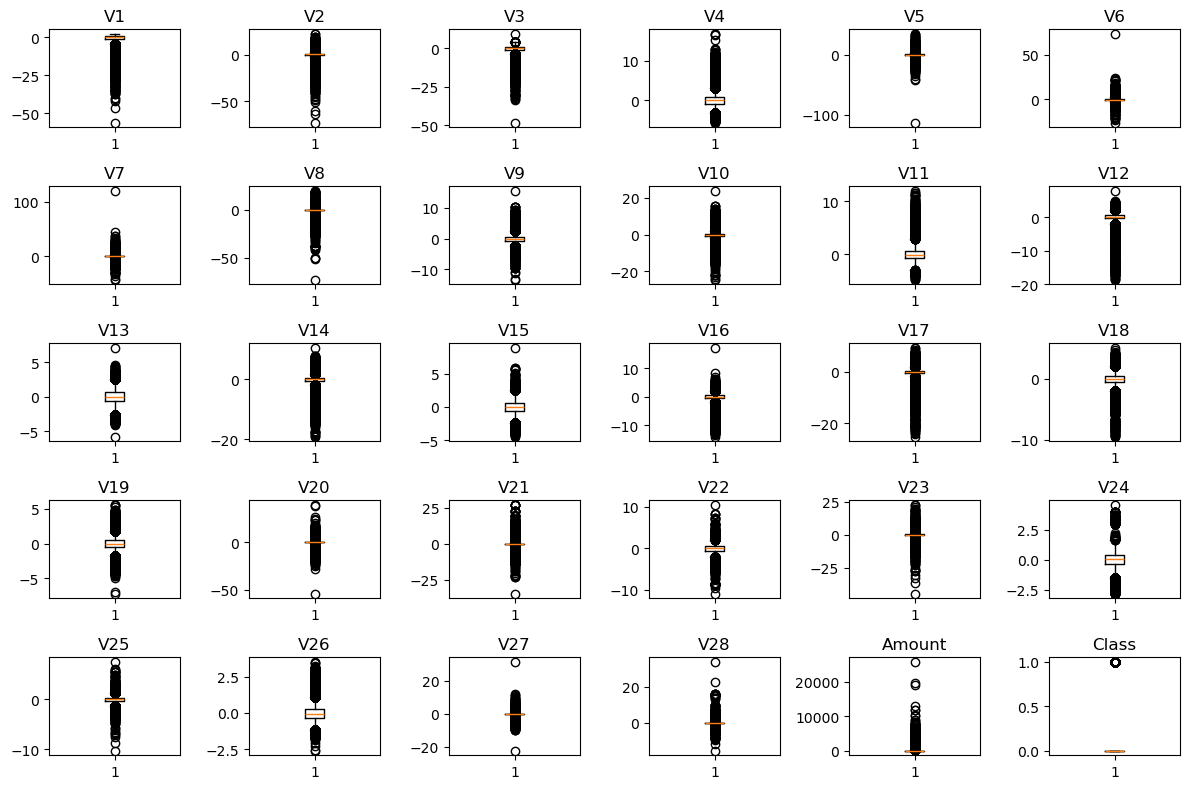

In [99]:
fig, axes = plt.subplots(5, 6, figsize=(12, 8))
df_col_index = 0

for rows in range(0,5):
    for column in range(0,6):
        if df_fraud.columns[df_col_index] == 'Time':
            df_col_index += 1
        axes[rows, column].boxplot(df_fraud.iloc[:, df_col_index])
        axes[rows, column].set_title(df_fraud.columns[df_col_index])
        df_col_index += 1
        
plt.tight_layout()
plt.show()

Kesimpulan : Untuk V1, karena base model bisa menerima outlier, maka asumsi awal nilai outlier memang valid, sehingga tidak diperlukan transformasi lanjutan untuk awalan

### 2.3.4 Invalid Values Check

In [100]:
# Cek apakah ada time yang minus

df_fraud[df_fraud['Time'] < 0]

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class


In [101]:
# Cek min dan max untuk V1 sampai V28

df_fraud.loc[:, ~df_fraud.columns.isin(['Time', 'Amount', 'Class'])].describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28
count,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05
mean,1.168375e-15,3.416908e-16,-1.379537e-15,2.074095e-15,9.604066e-16,1.487313e-15,-5.556467e-16,1.213481e-16,-2.406331e-15,2.239053e-15,...,1.039917e-15,6.406204e-16,1.654067e-16,-3.568593e-16,2.578648e-16,4.473266e-15,5.340915e-16,1.683437e-15,-3.660091e-16,-1.227390e-16
std,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,...,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01
min,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,...,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01
25%,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,...,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02
50%,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,...,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02
75%,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,...,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02
max,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,...,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01


In [102]:
df_fraud[df_fraud['Amount'] < 0]

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class


In [103]:
# Sanity Check Amount

df_fraud[df_fraud['Amount'] == 0]

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
383,282.0,-0.356466,0.725418,1.971749,0.831343,0.369681,-0.107776,0.751610,-0.120166,-0.420675,...,0.020804,0.424312,-0.015989,0.466754,-0.809962,0.657334,-0.043150,-0.046401,0.0,0
514,380.0,-1.299837,0.881817,1.452842,-1.293698,-0.025105,-1.170103,0.861610,-0.193934,0.592001,...,-0.272563,-0.360853,0.223911,0.598930,-0.397705,0.637141,0.234872,0.021379,0.0,0
534,403.0,1.237413,0.512365,0.687746,1.693872,-0.236323,-0.650232,0.118066,-0.230545,-0.808523,...,-0.077543,-0.178220,0.038722,0.471218,0.289249,0.871803,-0.066884,0.012986,0.0,0
541,406.0,-2.312227,1.951992,-1.609851,3.997906,-0.522188,-1.426545,-2.537387,1.391657,-2.770089,...,0.517232,-0.035049,-0.465211,0.320198,0.044519,0.177840,0.261145,-0.143276,0.0,1
575,430.0,-1.860258,-0.629859,0.966570,0.844632,0.759983,-1.481173,-0.509681,0.540722,-0.733623,...,0.268028,0.125515,-0.225029,0.586664,-0.031598,0.570168,-0.043007,-0.223739,0.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
283719,171817.0,-0.750414,0.904175,0.996461,0.427284,1.720336,0.929256,0.794272,0.176719,-1.836261,...,0.050750,0.115532,-0.623995,-0.186896,0.733759,2.558151,-0.188835,0.001654,0.0,0
283782,171870.0,2.083677,-0.065811,-1.442870,0.135416,0.043035,-1.306975,0.335835,-0.371635,0.730560,...,-0.147536,-0.246599,0.194758,-0.082277,0.012887,-0.069278,-0.048995,-0.065482,0.0,0
283949,172027.0,2.132569,-0.057836,-1.724522,-0.030326,0.412146,-0.903088,0.345843,-0.348132,0.722638,...,-0.188739,-0.343876,0.105024,-0.763831,0.117381,-0.027682,-0.047514,-0.071700,0.0,0
284085,172140.0,-2.210521,-1.039425,0.189704,-1.291932,3.742120,-1.665061,3.120388,-2.324089,0.364926,...,-0.286359,1.326003,-0.361764,-0.268117,1.051309,0.334629,-1.930149,-0.899888,0.0,0


In [104]:
df_fraud['Class'].unique()

array([0, 1])

Kesimpulan :

Untuk Time, aman tidak ada yang negatif

Untuk V1 - V28, semua merata untuk negatif tak hingga dan positif tak hingga valid karena hasil PCA

Untuk Amount, aman tidak ada yang negatif

Untuk Class, aman karena sudah sesuai hanya ada class 0 dan class 1

### 2.3.4 Invalid Dtypes Check

In [105]:
## Check is data success imported

df_fraud.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

Kesimpulan:

Untuk V1 - Class sudah aman

Untuk Time, karena berdasarkan keterangan penyedia merupakan selisih, maka sudah benar menggunakan float (antisipasi selisih desimal)

### 2.3.4 Inconsistency Check

Karena kolom kategori hanya ada Class, dan sudah dilakukan pengecekan sebelumnya, maka data ini aman dari error Inconsistency

## 2.4 Bagaimana distribusi datanya?

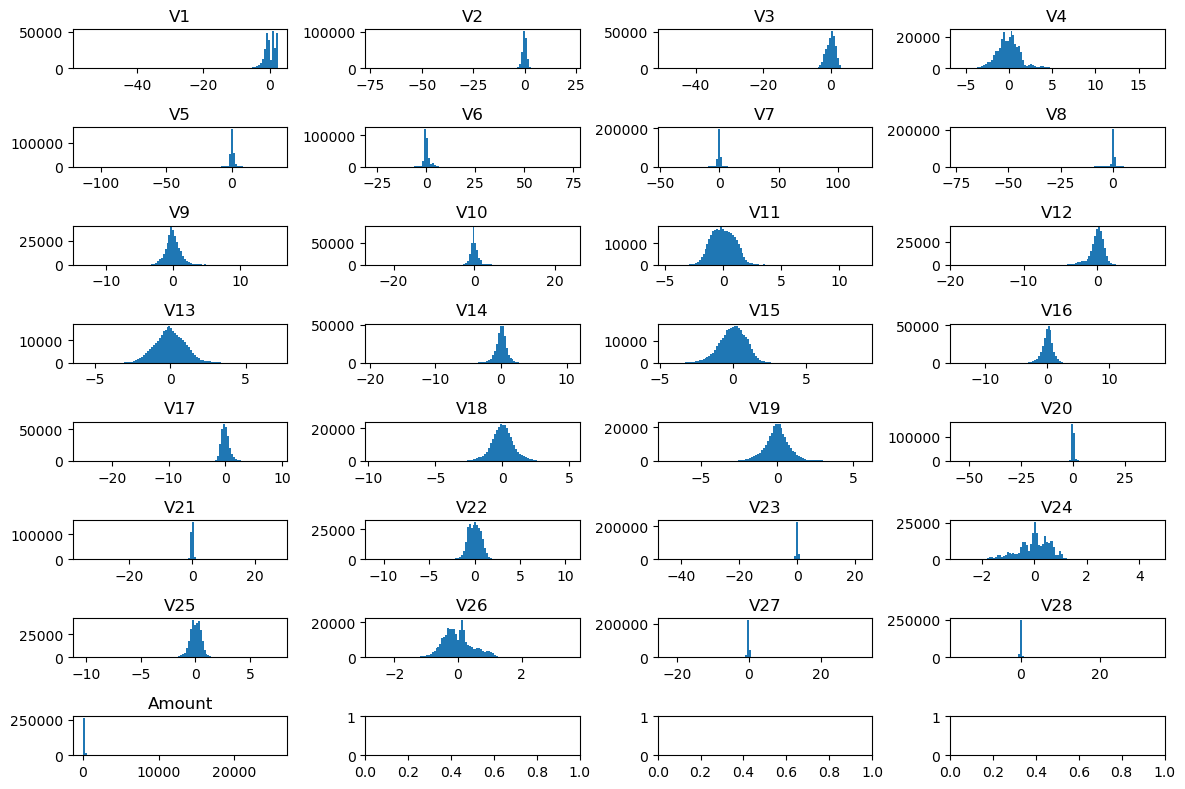

In [106]:
fig, axes = plt.subplots(8, 4, figsize=(12,8))

index_df_col = 1

for row in range(0,8):
    for column in range(0,4):
        if axes[row, column] == axes[7, 1]:
            break
        axes[row, column].hist(df_fraud.iloc[:, index_df_col], bins=100)
        axes[row, column].set_title(df_fraud.columns[index_df_col])
        index_df_col += 1

plt.tight_layout()
plt.show()

In [107]:
column_tidak_dist_normal = []

for col in df_fraud.columns:
    if col != 'Class':
        if (df_fraud[col].skew() >= 1) or (df_fraud[col].skew() <= -1):
            column_tidak_dist_normal.append(col)
            print(col,'\t:',df_fraud[col].skew())

V1 	: -3.2806673027560405
V2 	: -4.624865573285336
V3 	: -2.2401554402404193
V5 	: -2.425901495952054
V6 	: 1.826580664998085
V7 	: 2.553907417429514
V8 	: -8.521944194777976
V10 	: 1.1871405899625278
V12 	: -2.278400935410618
V14 	: -1.9951758402683304
V16 	: -1.100966276051066
V17 	: -3.8449144738706202
V20 	: -2.037155299081399
V21 	: 3.5929911930778453
V23 	: -5.875140340106818
V27 	: -1.1702089424327133
V28 	: 11.19209119221281
Amount 	: 16.977724453761024


In [108]:
print(column_tidak_dist_normal)

['V1', 'V2', 'V3', 'V5', 'V6', 'V7', 'V8', 'V10', 'V12', 'V14', 'V16', 'V17', 'V20', 'V21', 'V23', 'V27', 'V28', 'Amount']


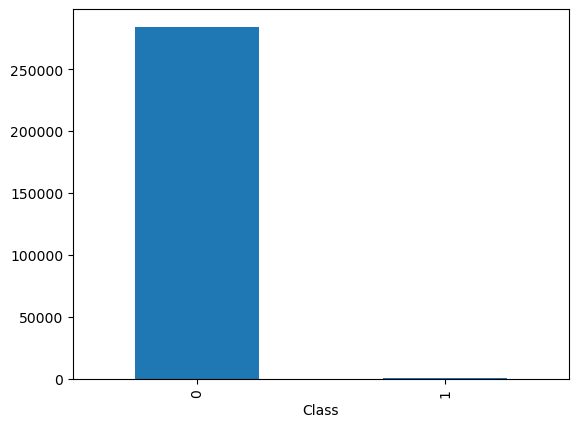

In [109]:
df_fraud['Class'].value_counts().plot.bar()
plt.show()

Kesimpulan : 

Ada beberapa kolom yang tidak terdistribusi normal meskipun hasil perhitungan PCA.

Juga untuk Class nya sangat jauh sekali imbalance nya

## 2.5 Bagaimana Variansi datanya?

In [110]:
df_fraud.var(numeric_only=True)

Time      2.255124e+09
V1        3.836489e+00
V2        2.726820e+00
V3        2.299029e+00
V4        2.004684e+00
V5        1.905081e+00
V6        1.774946e+00
V7        1.530401e+00
V8        1.426479e+00
V9        1.206992e+00
V10       1.185594e+00
V11       1.041855e+00
V12       9.984034e-01
V13       9.905708e-01
V14       9.189055e-01
V15       8.378034e-01
V16       7.678191e-01
V17       7.213734e-01
V18       7.025394e-01
V19       6.626619e-01
V20       5.943254e-01
V21       5.395255e-01
V22       5.266428e-01
V23       3.899507e-01
V24       3.668084e-01
V25       2.717308e-01
V26       2.325429e-01
V27       1.629192e-01
V28       1.089550e-01
Amount    6.256007e+04
Class     1.724507e-03
dtype: float64

Kesimpulan : 
- Untuk feature V1 - V28, karena merupakan hasil PCA, maka sudah valid karena semakin tinggi nilai V, semakin turun nilai variansi nya

- Untuk Amount memiliki variansi yang tinggi memberikan indikasi bahwa transaksi memang terjadi dengan nilai yang sangat beragam.

# Summary Hasil Pengecekan Berdasarkan Pemahaman pada Data

- Karakteristik Data merupakan Data Width dengan representasi 1 baris == 1 event.

- Permasalahan data yakni terdapat 1081 data duplicates

- Semua feature (kecuali feature time memiliki outlier)

- Terdapat baris dimana Amount == 0

- Untuk pengecekan variansi, untuk setiap feature aman, tidak ada feature yang memiliki variansi 0

- 18 kolom yang tidak terdistribusi normal. Kolom yang tidak terdistribusi normal antara lain:

    V1, V2, V3, V5, V6, V7, V8, V10, V12, V14, V16, V17, V20, V21, V23, V27, V28, dan Amount

In [111]:
df_fraud.to_csv(r'..\Data\result\01_Business_&_Data_Understanding.csv', index=False)